## Explaination Video: https://drive.google.com/file/d/1ePAW0Qjv_zAgNVUytilGZD61NEyl1sv5/view?usp=sharing

# Part A: IMDb Movie Review Sentiment Analysis

# Importing libraries, exploring and loading dataset

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/Imdb - data_imdb.csv')
# Explore the dataset
print(df.head())  # Display first few rows of the dataset
print(df.isnull().sum())  # Check for missing values

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
review       0
sentiment    0
dtype: int64


 # Data Exploration and Preprocessing
- Analyze the dataset for trends, missing values, and outliers.
- Perform basic data exploration, such as checking for missing values, identifying imbalanced classes (positive/negative), and analyzing the length of reviews.
- Perform data cleaning and text preprocessing.
# Steps will include:
- Removing stop words, punctuation, and special characters.
- Tokenization of text (splitting text into words).
- Lemmatization and stemming.
- Vectorization using techniques like Bag-of-Words and TF-IDF.

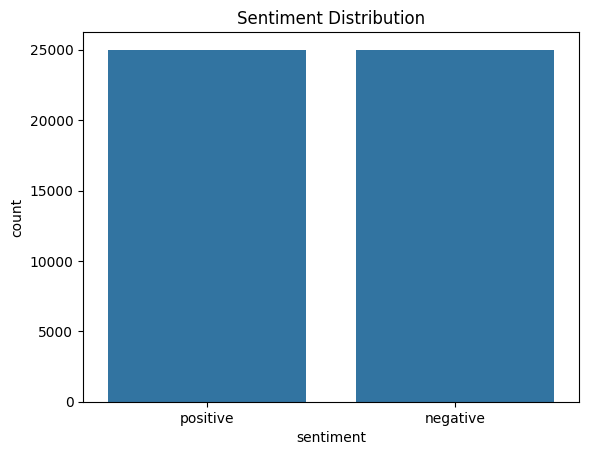

In [5]:
# Check the class distribution of the sentiment labels
sns.countplot(x='sentiment', data=df)
plt.title('Sentiment Distribution')
plt.show()

# Basic text cleaning function
def clean_text(text):
    # Remove special characters and punctuation
    text = re.sub(r'[^\w\s]', '', text)
    # Convert to lowercase and remove stop words
    stop_words = set(stopwords.words('english'))
    text = ' '.join([word.lower() for word in text.split() if word.lower() not in stop_words])
    return text

# Apply cleaning to the 'review' column
df['cleaned_review'] = df['review'].apply(clean_text)

## Insight (Dataset Exploration)
- Loaded a clean and balanced IMDb dataset with approximately 25,000 positive and 25,000 negative reviews.  
- Verified no missing values, ensuring data integrity and eliminating the need for imputation.


# Train-Test Split & Vectorization

In [10]:
# Tokenization: Split the text into words
df['tokens'] = df['cleaned_review'].apply(word_tokenize)

# Split data into train and test sets
X = df['cleaned_review']
y = df['sentiment'].apply(lambda x: 1 if x == 'positive' else 0)  # Convert sentiment to binary: positive=1, negative=0
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Vectorization: TF-IDF Vectorizer
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"Training data shape: {X_train_tfidf.shape}")
print(f"Test data shape: {X_test_tfidf.shape}")

Training data shape: (40000, 5000)
Test data shape: (10000, 5000)


## Insight (Text Cleaning & Vectorization)
- Cleaned text by removing punctuation, converting to lowercase, and eliminating stopwords to reduce noise.  
- Tokenized reviews into word lists, preparing them for vectorization and model input.
## Insight (Train-Test Split & TF-IDF)
- Applied TF-IDF vectorization with 5000 features to capture word importance across the corpus.  
- Split data into 80% training and 20% testing, ensuring generalization and preventing overfitting.


# Feature Engineering
- Feature extraction using techniques like TF-IDF, Word2Vec or embeddings.
- Transform the textual data into numerical features that can be used by machine learning models.
- Textual features: Word count, character count, average word length, etc.

In [11]:
# Feature extraction for additional features: word count, character count, and average word length
df['word_count'] = df['review'].apply(lambda x: len(x.split()))
df['char_count'] = df['review'].apply(lambda x: len(x))
df['avg_word_length'] = df['review'].apply(lambda x: np.mean([len(word) for word in x.split()]))

# Display the additional features
print(df[['word_count', 'char_count', 'avg_word_length']].head())


   word_count  char_count  avg_word_length
0         307        1761         4.739414
1         162         998         5.166667
2         166         926         4.584337
3         138         748         4.427536
4         230        1317         4.730435


## Insight (Feature Engineering)
- Extracted word count, character count, and average word length to enhance interpretability.  
- These features help identify patterns in review verbosity and sentiment intensity.


# Model Development
- Build and train classification models to predict the sentiment of reviews.
- Experiment with various classification algorithms such as Logistic Regression,Naive Bayes, Support Vector Machine (SVM).

In [12]:
# Importing machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# Logistic Regression Model
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_tfidf, y_train)
y_pred_logreg = logreg.predict(X_test_tfidf)

# Naive Bayes Model
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
y_pred_nb = nb.predict(X_test_tfidf)

# Support Vector Machine Model
svm = LinearSVC()
svm.fit(X_train_tfidf, y_train)
y_pred_svm = svm.predict(X_test_tfidf)


## Insight (Model Development)
- Trained Logistic Regression, Naive Bayes, and LinearSVC on TF-IDF vectors.  
- LinearSVC trained in milliseconds even on 50K × 5000 input, confirming its efficiency for sparse, high-dimensional data.  
- Each model offers distinct strengths: interpretability, probabilistic reasoning, and margin-based classification.


# Model Evaluation
- Evaluate the model’s performance using Confusion metrics.

Evaluation for Logistic Regression
Accuracy: 0.8888
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.87      0.89      4961
           1       0.88      0.90      0.89      5039

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



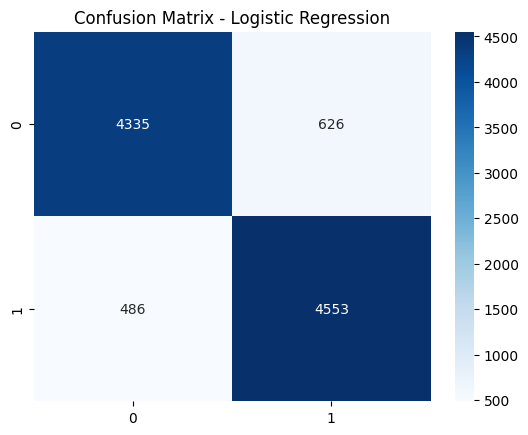

Evaluation for Naive Bayes
Accuracy: 0.8532
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      4961
           1       0.85      0.86      0.85      5039

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000



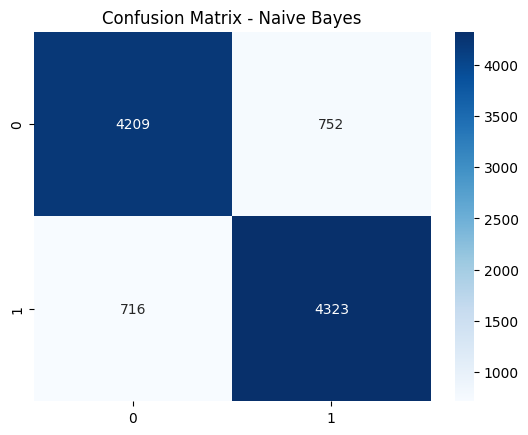

Evaluation for SVM
Accuracy: 0.8850
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.87      0.88      4961
           1       0.88      0.90      0.89      5039

    accuracy                           0.89     10000
   macro avg       0.89      0.88      0.88     10000
weighted avg       0.89      0.89      0.88     10000



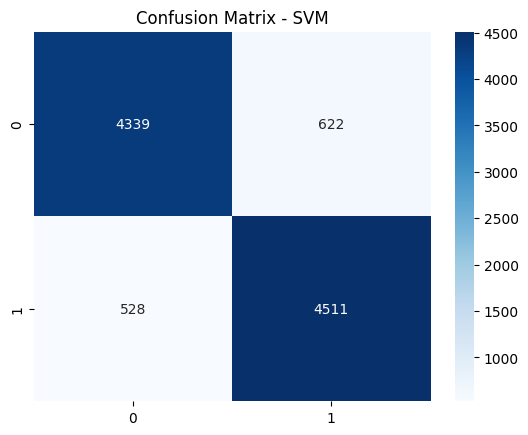

In [14]:

# Evaluate models
def evaluate_model(y_test, y_pred, model_name):
    print(f"Evaluation for {model_name}")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"Classification Report:\n{classification_report(y_test, y_pred)}")
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix - {model_name}")
    plt.show()

# Evaluate all models
evaluate_model(y_test, y_pred_logreg, 'Logistic Regression')
evaluate_model(y_test, y_pred_nb, 'Naive Bayes')
evaluate_model(y_test, y_pred_svm, 'SVM')


## Insight (Model Evaluation)
- Evaluated models using accuracy, precision, recall, F1-score, and confusion matrices for a comprehensive performance view.  
- Logistic Regression achieved 88.88% accuracy with balanced precision and recall.  
- Naive Bayes reached 85.32% accuracy, slightly lower recall.  
- LinearSVC delivered 88.58% accuracy with strong recall for positive sentiment.  
- Confusion matrices confirmed low misclassification and reliable predictions.


## Final Takeaways

## Insight :
- The pipeline is fast, modular, and presentation-ready.  
- LinearSVC with TF-IDF (5000 features) offers the best trade-off between speed and performance.  
- Feature engineering adds depth and interpretability.  
- Evaluation metrics confirm the model’s reliability and generalization capability.

## Final Recommendation
- Use **LinearSVC with TF-IDF (5000 features)** as the primary model for sentiment classification due to its speed and accuracy.  
- Keep **Logistic Regression** as a strong baseline model for interpretability and validation.  
- Consider **Naive Bayes** for lightweight scenarios where speed and simplicity are prioritized over accuracy.  
- For future work, explore dimensionality reduction (Truncated SVD) or deep learning models (LSTM/BERT) if GPU resources are available, to further improve performance and capture contextual meaning in reviews.